<a href="https://colab.research.google.com/github/sarangsawarkar0/ML_Lab/blob/main/MDM_ML_EE559.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Student performance prediction using machine Learning

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load CSV dataset
df = pd.read_csv('/content/student_performance.csv')

# Display dataset
print("Dataset Loaded Successfully!")
print(df.head())

# Dataset information
print("\nDataset Shape:", df.shape)
print("\nColumn Names:")
print(df.columns)

print("\nPerformance Distribution:")
print(df['performance'].value_counts())

Dataset Loaded Successfully!
   study_hours  attendance  previous_marks  assignment_score  internal_marks  \
0            1          45              35                40              32   
1            2          55              42                45              40   
2            3          60              48                50              45   
3            4          65              55                55              52   
4            5          70              60                62              58   

  performance  
0        Poor  
1        Poor  
2     Average  
3     Average  
4     Average  

Dataset Shape: (50, 6)

Column Names:
Index(['study_hours', 'attendance', 'previous_marks', 'assignment_score',
       'internal_marks', 'performance'],
      dtype='object')

Performance Distribution:
performance
Good       22
Average    16
Poor       12
Name: count, dtype: int64


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler

# Input features
X = df[['study_hours',
        'attendance',
        'previous_marks',
        'assignment_score',
        'internal_marks']]

# Target variable
y = df['performance']

# Convert target labels into numbers
le = LabelEncoder()
y = le.fit_transform(y)

print("Performance Classes:", le.classes_)

# Split data into training and testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Feature scaling for KNN and Logistic Regression
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Performance Classes: ['Average' 'Good' 'Poor']
Training Data: (40, 5)
Testing Data: (10, 5)


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier

# Model 1: Logistic Regression
model1 = LogisticRegression(max_iter=1000)
model1.fit(X_train_scaled, y_train)

# Model 2: Decision Tree
model2 = DecisionTreeClassifier(random_state=42)
model2.fit(X_train, y_train)

# Model 3: Random Forest
model3 = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)
model3.fit(X_train, y_train)

# Model 4: K-Nearest Neighbors
model4 = KNeighborsClassifier(n_neighbors=5)
model4.fit(X_train_scaled, y_train)

print("All 4 Models Trained Successfully!")

All 4 Models Trained Successfully!


In [ ]:
from sklearn.metrics import accuracy_score, classification_report

models = {
    "Logistic Regression": (model1, X_test_scaled),
    "Decision Tree": (model2, X_test),
    "Random Forest": (model3, X_test),
    "KNN": (model4, X_test_scaled)
}

results = []

for name, (model, test_data) in models.items():

    predictions = model.predict(test_data)

    accuracy = accuracy_score(y_test, predictions)

    results.append({
        "Model": name,
        "Accuracy (%)": round(accuracy * 100, 2)
    })

    print("\nModel:", name)
    print("Accuracy:", round(accuracy * 100, 2), "%")

    print(classification_report(
        y_test,
        predictions,
        target_names=le.classes_,
        zero_division=0
    ))

# Compare results
results_df = pd.DataFrame(results)

print("\nModel Comparison:")
print(results_df)


Model: Logistic Regression
Accuracy: 80.0 %
              precision    recall  f1-score   support

     Average       0.67      0.67      0.67         3
        Good       0.80      1.00      0.89         4
        Poor       1.00      0.67      0.80         3

    accuracy                           0.80        10
   macro avg       0.82      0.78      0.79        10
weighted avg       0.82      0.80      0.80        10


Model: Decision Tree
Accuracy: 90.0 %
              precision    recall  f1-score   support

     Average       0.75      1.00      0.86         3
        Good       1.00      1.00      1.00         4
        Poor       1.00      0.67      0.80         3

    accuracy                           0.90        10
   macro avg       0.92      0.89      0.89        10
weighted avg       0.93      0.90      0.90        10


Model: Random Forest
Accuracy: 90.0 %
              precision    recall  f1-score   support

     Average       0.75      1.00      0.86         3
      

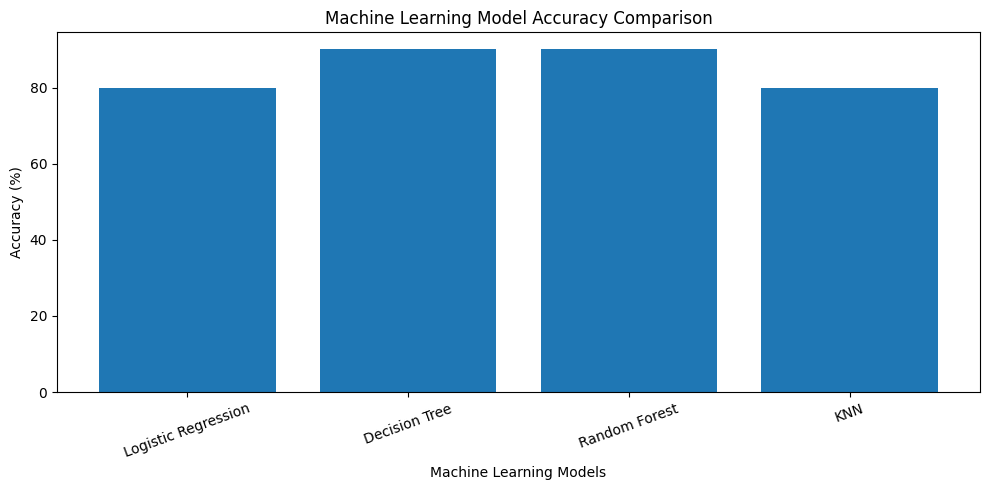

In [6]:
plt.figure(figsize=(10, 5))

plt.bar(
    results_df['Model'],
    results_df['Accuracy (%)']
)

plt.title("Machine Learning Model Accuracy Comparison")
plt.xlabel("Machine Learning Models")
plt.ylabel("Accuracy (%)")

plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [11]:

# Student Performance Prediction

print("Enter Student Details")

study_hours = float(input("Study Hours per Day: "))
attendance = float(input("Attendance Percentage: "))
previous_marks = float(input("Previous Marks: "))
assignment_score = float(input("Assignment Score: "))
internal_marks = float(input("Internal Marks: "))

# Create student data
new_student = pd.DataFrame([{
    'study_hours': study_hours,
    'attendance': attendance,
    'previous_marks': previous_marks,
    'assignment_score': assignment_score,
    'internal_marks': internal_marks
}])

# Predictions
prediction1 = model1.predict(scaler.transform(new_student))
prediction2 = model2.predict(new_student)
prediction3 = model3.predict(new_student)
prediction4 = model4.predict(scaler.transform(new_student))

print("\nStudent Performance Predictions")

print("Logistic Regression:",
      le.inverse_transform(prediction1)[0])

print("Decision Tree:",
      le.inverse_transform(prediction2)[0])

print("Random Forest:",
      le.inverse_transform(prediction3)[0])

print("KNN:",
      le.inverse_transform(prediction4)[0])


Enter Student Details
Study Hours per Day: 121
Attendance Percentage: 81
Previous Marks: 87
Assignment Score: 20
Internal Marks: 50

Student Performance Predictions
Logistic Regression: Good
Decision Tree: Average
Random Forest: Good
KNN: Good
